In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:

test_guests = {
    "Family Guest": pd.DataFrame([{
        "family": 1,
        "long_stay": 1,
        "business": 0,
        "airport_arrival": 0,
        "spa_interest": 0,
        "breakfast_need": 1,
        "standard_room": 1
    }]),

    "Business Guest": pd.DataFrame([{
        "family": 0,
        "long_stay": 0,
        "business": 1,
        "airport_arrival": 1,
        "spa_interest": 0,
        "breakfast_need": 0,
        "standard_room": 1
    }]),

    "Long-Stay Guest": pd.DataFrame([{
        "family": 0,
        "long_stay": 1,
        "business": 0,
        "airport_arrival": 0,
        "spa_interest": 1,
        "breakfast_need": 1,
        "standard_room": 0
    }]),

    "Short-Stay Guest": pd.DataFrame([{
        "family": 0,
        "long_stay": 0,
        "business": 0,
        "airport_arrival": 1,
        "spa_interest": 0,
        "breakfast_need": 1,
        "standard_room": 1
    }])
}


In [10]:

def guestly_recommendations(guest_profile, top_n=3):

    recommendations = recommend_for_guest(
        guest_profile,
        top_n
    )

    recommendations["reason"] = recommendations["service_name"].apply(
        lambda service: explain_recommendation(
            service,
            guest_profile
        )
    )

    return recommendations


In [16]:

def recommend_for_guest(guest_profile, top_n=3):

    scores = cosine_similarity(
        guest_profile[feature_columns],
        service_features[feature_columns]
    )[0]

    results = pd.DataFrame({
        "service_name": service_features["service_name"],
        "similarity_score": scores
    })

    results = results[results["similarity_score"] > 0]

    results = results.sort_values(
        by="similarity_score",
        ascending=False
    )

    return results.head(top_n).reset_index(drop=True)


In [19]:
def guestly_recommendations(guest_profile, top_n=3):

    recommendations = recommend_for_guest(guest_profile, top_n)

    recommendations["reason"] = recommendations["service_name"].apply(
        lambda service: explain_recommendation(service, guest_profile)
    )

    return recommendations

In [22]:
feature_columns = [
    "family",
    "long_stay",
    "business",
    "airport_arrival",
    "spa_interest",
    "breakfast_need",
    "standard_room"
]

print("Feature columns defined successfully.")

Feature columns defined successfully.


In [27]:

service_features = pd.DataFrame({
    "service_name": [
        "Breakfast Package",
        "Airport Pickup",
        "Spa Package",
        "Late Checkout",
        "Room Upgrade",
        "Laundry Service",
        "Family Package"
    ],

    "family": [1, 0, 0, 0, 0, 0, 1],
    "long_stay": [1, 0, 0, 1, 0, 1, 1],
    "business": [0, 1, 0, 1, 1, 0, 0],
    "airport_arrival": [0, 1, 0, 0, 0, 0, 0],
    "spa_interest": [0, 0, 1, 0, 0, 0, 0],
    "breakfast_need": [1, 0, 0, 0, 0, 0, 1],
    "standard_room": [0, 0, 0, 0, 1, 0, 0]
})

print("Service feature matrix restored.")
display(service_features)


Service feature matrix restored.


,service_name,family,long_stay,business,airport_arrival,spa_interest,breakfast_need,standard_room
0,Breakfast Package,1,1,0,0,0,1,0
1,Airport Pickup,0,0,1,1,0,0,0
2,Spa Package,0,0,0,0,1,0,0
3,Late Checkout,0,1,1,0,0,0,0
4,Room Upgrade,0,0,1,0,0,0,1
5,Laundry Service,0,1,0,0,0,0,0
6,Family Package,1,1,0,0,0,1,0


In [28]:
feature_columns = [
    "family",
    "long_stay",
    "business",
    "airport_arrival",
    "spa_interest",
    "breakfast_need",
    "standard_room"
]

display(service_features[feature_columns])

,family,long_stay,business,airport_arrival,spa_interest,breakfast_need,standard_room
0,1,1,0,0,0,1,0
1,0,0,1,1,0,0,0
2,0,0,0,0,1,0,0
3,0,1,1,0,0,0,0
4,0,0,1,0,0,0,1
5,0,1,0,0,0,0,0
6,1,1,0,0,0,1,0


In [29]:
import pandas as pd
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity

Guestly Upsell Engine is ready!
Welcome to Guestly!
Pandas version: 2.3.3
NumPy version: 2.2.5
All systems ready.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                  

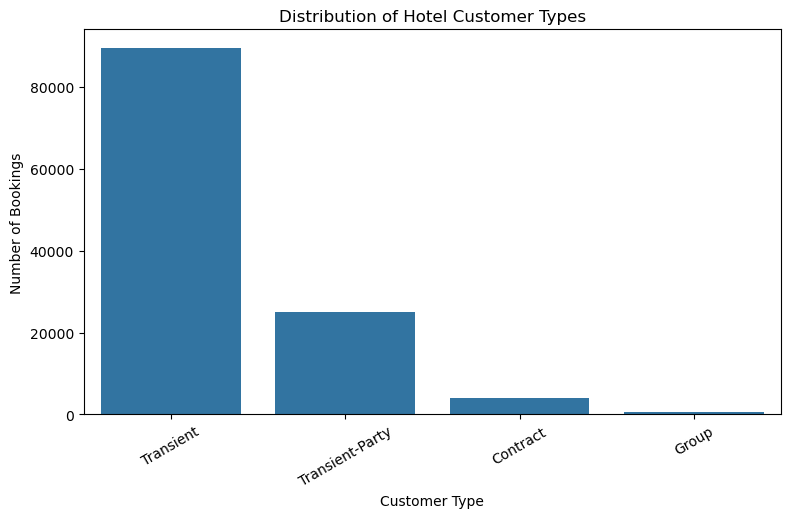

Backup created successfully.
Company and agent missing values handled.
Country missing values handled.
Children missing values handled.
Bookings with zero adults:
403

Bookings with negative room rates:
1

Bookings with zero nights:
715

Bookings with unusually large guest counts:
14
Duplicates: 31994
Original dataset shape: (119390, 32)
Cleaned dataset shape: (119390, 35)

Remaining missing values:
0

Duplicate records:
31994

New features:
['total_guests', 'total_nights', 'is_family']
Cleaned dataset saved successfully!
GUEST PROFILE
-------------------
adults: 2
children: 0.0
total_guests: 2.0
total_nights: 0
is_family: 0
customer_type: Transient
meal: BB
room_type: C
PERSONALIZED RECOMMENDATIONS
----------------------------
- Late Checkout


In [33]:
%run ../notebooks/guestly_upsell_engine.ipynb

In [44]:
print("test_guests:", "test_guests" in globals())
print("recommend_for_guest:", "recommend_for_guest" in globals())
print("explain_recommendation:", "explain_recommendation" in globals())
print("guestly_recommendations:", "guestly_recommendations" in globals())
print("service_features:", "service_features" in globals())
print("feature_columns:", "feature_columns" in globals())
print("cosine_similarity:", "cosine_similarity" in globals())
print("pandas:", "pd" in globals())

test_guests: True
recommend_for_guest: True
explain_recommendation: False
guestly_recommendations: True
service_features: True
feature_columns: True
cosine_similarity: True
pandas: True


In [45]:

def explain_recommendation(service_name, guest):

    explanations = {
        "Breakfast Package": "This guest may benefit from an additional breakfast option.",
        "Airport Pickup": "Airport pickup may provide convenient transportation.",
        "Spa Package": "This service matches the guest's wellness interest.",
        "Late Checkout": "Late checkout may provide additional flexibility.",
        "Room Upgrade": "The guest's room profile suggests an upgrade may be relevant.",
        "Laundry Service": "This service may be useful for longer stays.",
        "Family Package": "This package may suit guests travelling with children."
    }

    return explanations.get(
        service_name,
        "This service matches some features of the guest profile."
    )

print("Explanation function created successfully.")


Explanation function created successfully.


In [46]:
def guestly_recommendations(guest_profile, top_n=3):

    recommendations = recommend_for_guest(guest_profile, top_n)

    recommendations["reason"] = recommendations["service_name"].apply(
        lambda service: explain_recommendation(service, guest_profile)
    )

    return recommendations

In [47]:
all_test_results = []

for guest_type, profile in test_guests.items():

    recommendations = guestly_recommendations(profile)

    recommendations["guest_type"] = guest_type

    all_test_results.append(recommendations)

evaluation_results = pd.concat(all_test_results, ignore_index=True)

display(evaluation_results)

,service_name,similarity_score,reason,guest_type
0,Breakfast Package,0.866025,This guest may benefit from an additional brea...,Family Guest
1,Family Package,0.866025,This package may suit guests travelling with c...,Family Guest
2,Laundry Service,0.500000,This service may be useful for longer stays.,Family Guest
3,Airport Pickup,0.816497,Airport pickup may provide convenient transpor...,Business Guest
4,Room Upgrade,0.816497,The guest's room profile suggests an upgrade m...,Business Guest
5,Late Checkout,0.408248,Late checkout may provide additional flexibility.,Business Guest
6,Breakfast Package,0.666667,This guest may benefit from an additional brea...,Long-Stay Guest
7,Family Package,0.666667,This package may suit guests travelling with c...,Long-Stay Guest
8,Spa Package,0.577350,This service matches the guest's wellness inte...,Long-Stay Guest
9,Airport Pickup,0.408248,Airport pickup may provide convenient transpor...,Short-Stay Guest


In [48]:
import os

os.makedirs("../outputs", exist_ok=True)

evaluation_results.to_csv(
    "../outputs/guestly_evaluation_results.csv",
    index=False
)

print("Guestly evaluation saved successfully.")

Guestly evaluation saved successfully.


In [49]:
print("Total recommendations:", len(evaluation_results))

print("Duplicate recommendations:",
      evaluation_results.duplicated(
          subset=["guest_type", "service_name"]
      ).sum())

display(evaluation_results)

Total recommendations: 12
Duplicate recommendations: 0


,service_name,similarity_score,reason,guest_type
0,Breakfast Package,0.866025,This guest may benefit from an additional brea...,Family Guest
1,Family Package,0.866025,This package may suit guests travelling with c...,Family Guest
2,Laundry Service,0.500000,This service may be useful for longer stays.,Family Guest
3,Airport Pickup,0.816497,Airport pickup may provide convenient transpor...,Business Guest
4,Room Upgrade,0.816497,The guest's room profile suggests an upgrade m...,Business Guest
5,Late Checkout,0.408248,Late checkout may provide additional flexibility.,Business Guest
6,Breakfast Package,0.666667,This guest may benefit from an additional brea...,Long-Stay Guest
7,Family Package,0.666667,This package may suit guests travelling with c...,Long-Stay Guest
8,Spa Package,0.577350,This service matches the guest's wellness inte...,Long-Stay Guest
9,Airport Pickup,0.408248,Airport pickup may provide convenient transpor...,Short-Stay Guest


In [50]:

def guestly_api_recommendation(guest_profile):

    recommendations = guestly_recommendations(
        guest_profile,
        top_n=3
    )

    output = []

    for _, row in recommendations.iterrows():

        output.append({
            "service_name": row["service_name"],
            "similarity_score": round(
                float(row["similarity_score"]), 3
            ),
            "reason": row["reason"]
        })

    return {
        "status": "success",
        "recommendations": output
    }


In [51]:
family_api_result = guestly_api_recommendation(sample_guest)

print(family_api_result)

NameError: name 'sample_guest' is not defined

In [52]:
sample_guest = pd.DataFrame([{
    "family": 1,
    "long_stay": 1,
    "business": 0,
    "airport_arrival": 0,
    "spa_interest": 0,
    "breakfast_need": 1,
    "standard_room": 1
}])

print("Family guest profile restored.")
display(sample_guest)

Family guest profile restored.


,family,long_stay,business,airport_arrival,spa_interest,breakfast_need,standard_room
0,1,1,0,0,0,1,1


In [53]:
business_guest = pd.DataFrame([{
    "family": 0,
    "long_stay": 0,
    "business": 1,
    "airport_arrival": 1,
    "spa_interest": 0,
    "breakfast_need": 0,
    "standard_room": 1
}])

print("Business guest profile restored.")
display(business_guest)

Business guest profile restored.


,family,long_stay,business,airport_arrival,spa_interest,breakfast_need,standard_room
0,0,0,1,1,0,0,1


In [54]:
family_api_result = guestly_api_recommendation(sample_guest)

print(family_api_result)

{'status': 'success', 'recommendations': [{'service_name': 'Breakfast Package', 'similarity_score': 0.866, 'reason': 'This guest may benefit from an additional breakfast option.'}, {'service_name': 'Family Package', 'similarity_score': 0.866, 'reason': 'This package may suit guests travelling with children.'}, {'service_name': 'Laundry Service', 'similarity_score': 0.5, 'reason': 'This service may be useful for longer stays.'}]}


In [55]:
business_api_result = guestly_api_recommendation(business_guest)

print(business_api_result)

{'status': 'success', 'recommendations': [{'service_name': 'Airport Pickup', 'similarity_score': 0.816, 'reason': 'Airport pickup may provide convenient transportation.'}, {'service_name': 'Room Upgrade', 'similarity_score': 0.816, 'reason': "The guest's room profile suggests an upgrade may be relevant."}, {'service_name': 'Late Checkout', 'similarity_score': 0.408, 'reason': 'Late checkout may provide additional flexibility.'}]}


In [56]:
sample_guest = pd.DataFrame([{
    "family": 1,
    "long_stay": 1,
    "business": 0,
    "airport_arrival": 0,
    "spa_interest": 0,
    "breakfast_need": 1,
    "standard_room": 1
}])

business_guest = pd.DataFrame([{
    "family": 0,
    "long_stay": 0,
    "business": 1,
    "airport_arrival": 1,
    "spa_interest": 0,
    "breakfast_need": 0,
    "standard_room": 1
}])

In [57]:
print("FAMILY GUEST:")
print(guestly_api_recommendation(sample_guest))

print("\nBUSINESS GUEST:")
print(guestly_api_recommendation(business_guest))

FAMILY GUEST:
{'status': 'success', 'recommendations': [{'service_name': 'Breakfast Package', 'similarity_score': 0.866, 'reason': 'This guest may benefit from an additional breakfast option.'}, {'service_name': 'Family Package', 'similarity_score': 0.866, 'reason': 'This package may suit guests travelling with children.'}, {'service_name': 'Laundry Service', 'similarity_score': 0.5, 'reason': 'This service may be useful for longer stays.'}]}

BUSINESS GUEST:
{'status': 'success', 'recommendations': [{'service_name': 'Airport Pickup', 'similarity_score': 0.816, 'reason': 'Airport pickup may provide convenient transportation.'}, {'service_name': 'Room Upgrade', 'similarity_score': 0.816, 'reason': "The guest's room profile suggests an upgrade may be relevant."}, {'service_name': 'Late Checkout', 'similarity_score': 0.408, 'reason': 'Late checkout may provide additional flexibility.'}]}


In [58]:

import os

os.makedirs("../models", exist_ok=True)

engine_code = '''
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

feature_columns = [
    "family", "long_stay", "business",
    "airport_arrival", "spa_interest",
    "breakfast_need", "standard_room"
]

service_features = pd.DataFrame({
    "service_name": [
        "Breakfast Package", "Airport Pickup",
        "Spa Package", "Late Checkout",
        "Room Upgrade", "Laundry Service",
        "Family Package"
    ],
    "family": [1,0,0,0,0,0,1],
    "long_stay": [1,0,0,1,0,1,1],
    "business": [0,1,0,1,1,0,0],
    "airport_arrival": [0,1,0,0,0,0,0],
    "spa_interest": [0,0,1,0,0,0,0],
    "breakfast_need": [1,0,0,0,0,0,1],
    "standard_room": [0,0,0,0,1,0,0]
})

def recommend_for_guest(guest_profile, top_n=3):
    scores = cosine_similarity(
        guest_profile[feature_columns],
        service_features[feature_columns]
    )[0]

    results = pd.DataFrame({
        "service_name": service_features["service_name"],
        "similarity_score": scores
    })

    results = results[results["similarity_score"] > 0]
    results = results.sort_values(
        "similarity_score", ascending=False
    )

    return results.head(top_n).reset_index(drop=True)

def explain_recommendation(service_name, guest):
    explanations = {
        "Breakfast Package": "Additional breakfast option may be useful.",
        "Airport Pickup": "Convenient airport transportation.",
        "Spa Package": "Matches the recorded wellness interest.",
        "Late Checkout": "Provides additional checkout flexibility.",
        "Room Upgrade": "An upgrade may suit the guest's room preferences.",
        "Laundry Service": "Useful for guests staying longer.",
        "Family Package": "Suitable for guests travelling with children."
    }

    return explanations.get(service_name, "Matches guest profile.")

def guestly_recommendations(guest_profile, top_n=3):
    recommendations = recommend_for_guest(guest_profile, top_n)

    recommendations["reason"] = recommendations["service_name"].apply(
        lambda service: explain_recommendation(service, guest_profile)
    )

    return recommendations

def guestly_api_recommendation(guest_profile):
    recommendations = guestly_recommendations(guest_profile)

    return {
        "status": "success",
        "recommendations": recommendations.to_dict(orient="records")
    }
'''

with open("../models/guestly_recommendation_engine.py", "w") as file:
    file.write(engine_code)

print("Complete recommendation engine saved successfully.")


Complete recommendation engine saved successfully.


In [59]:
import os

print(os.path.exists("../models/guestly_recommendation_engine.py"))

True


In [60]:
import sys
import os

sys.path.append(os.path.abspath("../models"))

import guestly_recommendation_engine as guestly

print("Guestly engine imported successfully.")

Guestly engine imported successfully.


In [61]:
import pandas as pd

test_guest = pd.DataFrame([{
    "family": 1,
    "long_stay": 1,
    "business": 0,
    "airport_arrival": 0,
    "spa_interest": 0,
    "breakfast_need": 1,
    "standard_room": 1
}])

In [62]:
test_result = guestly.guestly_api_recommendation(test_guest)

print(test_result)

{'status': 'success', 'recommendations': [{'service_name': 'Breakfast Package', 'similarity_score': 0.8660254037844388, 'reason': 'Additional breakfast option may be useful.'}, {'service_name': 'Family Package', 'similarity_score': 0.8660254037844388, 'reason': 'Suitable for guests travelling with children.'}, {'service_name': 'Laundry Service', 'similarity_score': 0.5, 'reason': 'Useful for guests staying longer.'}]}


In [63]:
business_test = pd.DataFrame([{
    "family": 0,
    "long_stay": 0,
    "business": 1,
    "airport_arrival": 1,
    "spa_interest": 0,
    "breakfast_need": 0,
    "standard_room": 1
}])

business_result = guestly.guestly_api_recommendation(business_test)

print(business_result)

{'status': 'success', 'recommendations': [{'service_name': 'Airport Pickup', 'similarity_score': 0.816496580927726, 'reason': 'Convenient airport transportation.'}, {'service_name': 'Room Upgrade', 'similarity_score': 0.816496580927726, 'reason': "An upgrade may suit the guest's room preferences."}, {'service_name': 'Late Checkout', 'similarity_score': 0.408248290463863, 'reason': 'Provides additional checkout flexibility.'}]}


In [64]:
import json

json_output = json.dumps(test_result, indent=4)

print(json_output)

{
    "status": "success",
    "recommendations": [
        {
            "service_name": "Breakfast Package",
            "similarity_score": 0.8660254037844388,
            "reason": "Additional breakfast option may be useful."
        },
        {
            "service_name": "Family Package",
            "similarity_score": 0.8660254037844388,
            "reason": "Suitable for guests travelling with children."
        },
        {
            "service_name": "Laundry Service",
            "similarity_score": 0.5,
            "reason": "Useful for guests staying longer."
        }
    ]
}


In [65]:
import os

folders = ["../data", "../notebooks", "../models", "../outputs"]

for folder in folders:
    print(folder, ":", os.path.exists(folder))

print(
    "Recommendation engine:",
    os.path.exists("../models/guestly_recommendation_engine.py")
)

../data : True
../notebooks : True
../models : True
../outputs : True
Recommendation engine: True


In [66]:
def validate_guest_profile(guest_profile):
    required_columns = [
        "family",
        "long_stay",
        "business",
        "airport_arrival",
        "spa_interest",
        "breakfast_need",
        "standard_room"
    ]

    if not isinstance(guest_profile, pd.DataFrame):
        raise TypeError("Guest profile must be a pandas DataFrame.")

    missing_columns = [
        col for col in required_columns
        if col not in guest_profile.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    if len(guest_profile) != 1:
        raise ValueError("Provide exactly one guest profile.")

    if guest_profile[required_columns].isnull().any().any():
        raise ValueError("Guest profile contains missing values.")

    if not guest_profile[required_columns].isin([0, 1]).all().all():
        raise ValueError("Guest features must contain only 0 or 1.")

    return True

In [67]:
def guestly_api_recommendation(guest_profile):
    validate_guest_profile(guest_profile)

    recommendations = guestly_recommendations(guest_profile)

    return {
        "status": "success",
        "recommendations": recommendations.to_dict(orient="records")
    }

In [68]:
invalid_guest = pd.DataFrame([{
    "family": 1,
    "long_stay": 1,
    "business": 0
}])

try:
    print(guestly.guestly_api_recommendation(invalid_guest))
except Exception as error:
    print(type(error).__name__, ":", error)

KeyError : "['airport_arrival', 'spa_interest', 'breakfast_need', 'standard_room'] not in index"


In [69]:
import importlib
importlib.reload(guestly)

<module 'guestly_recommendation_engine' from 'C:\\Users\\user\\Guestly_Upsell_Engine\\models\\guestly_recommendation_engine.py'>